# 01 Bedrock Vadose-Zone Storage Capacity

Documents the neutron-probe storage workflow and generates the bedrock vadose-zone storage capacity figure and table. Frozen source exports are included in `Data/raw/`, and the processed storage time series used by the manuscript is written to `Data/storage_ts.csv`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import TheilSenRegressor
from scipy.interpolate import interp1d
from scipy.integrate import trapezoid
from scipy.optimize import curve_fit
import math
import os

sns.set_theme(style="ticks")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 10
})

# Build one daily site-precipitation record for all downstream analyses.
# Angelo days with at least 95% of the expected 5-minute observations are retained;
# PRISM supplies earlier years and fills incomplete Angelo days.
angelo_raw = pd.read_csv(
    './Data/angelo_precip_5m.csv', index_col=0, parse_dates=True
)['angelo-meadow-ws-rainfall-combined-mm']
angelo_raw = pd.to_numeric(angelo_raw, errors='coerce')
angelo_counts = angelo_raw.resample('D').count()
angelo_daily = angelo_raw.resample('D').sum(min_count=1).where(angelo_counts >= 274)

prism_raw = pd.read_csv('./Data/prism_ppt.csv', index_col=0, parse_dates=True)
prism_daily = pd.to_numeric(prism_raw.iloc[:, 0], errors='coerce') * 25.4

site_precip = pd.concat([
    angelo_daily.rename('angelo_mm'),
    prism_daily.rename('prism_mm'),
    angelo_counts.rename('angelo_observations')
], axis=1).sort_index()
site_precip['precip_mm'] = site_precip['angelo_mm'].combine_first(site_precip['prism_mm'])
site_precip['source'] = pd.Series(pd.NA, index=site_precip.index, dtype='object')
site_precip.loc[site_precip['prism_mm'].notna(), 'source'] = 'PRISM'
site_precip.loc[site_precip['angelo_mm'].notna(), 'source'] = 'Angelo'
site_precip = site_precip[site_precip['precip_mm'].notna()].copy()
site_precip.to_csv('./Data/site_precip_daily.csv', index_label='date')

overlap = site_precip['angelo_observations'].notna() & site_precip['prism_mm'].notna()
n_filled = ((site_precip['source'] == 'PRISM') & overlap).sum()
print(f'Wrote daily site precipitation; PRISM filled {n_filled} incomplete Angelo days.')

Wrote daily site precipitation; PRISM filled 45 incomplete Angelo days.


# Get the dynamic storage time series

Calibrated 46395 observations; retained 771/791 fixed-domain profiles.
 well  lower_m  upper_m  n_surveys  n_retained
    2     0.75      9.0         81          77
    5     0.75     10.0         85          84
    6     0.75      4.5         93          91
    7     0.75      4.0         97          96
   12     0.75      3.0         77          75
   13     0.75      5.0         81          81
   14     0.75      5.0         75          74
   15     0.75     10.0        107         104
   16     0.75     10.0         95          89


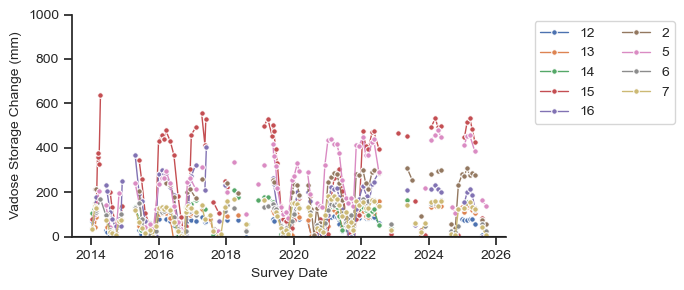

In [2]:
from neutron_probe_processing import process_neutron_profiles
from analysis_utils import well_colors
storage_ts = process_neutron_profiles('./Data')

# ==========================================
# 4. PLOTTING
# ==========================================
fig, ax = plt.subplots(figsize=(7, 3))

sns.lineplot(
    data=storage_ts,
    x='Date',
    y='Total Storage Change (mm)',
    hue='Hole ID',
    units='line_group',
    estimator=None,
    marker='o',
    markersize=4,
    linewidth=1,
    ax=ax
)

ax.axhline(0, color='black', linewidth=1.5)
ax.set_ylim(0, 1000)
ax.set_xlabel('Survey Date')
ax.set_ylabel('Vadose Storage Change (mm)')
ax.grid(False)
sns.despine(ax=ax)

ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)

plt.tight_layout()
plt.show()

storage_ts.to_csv("./Data/storage_ts.csv", index=False)

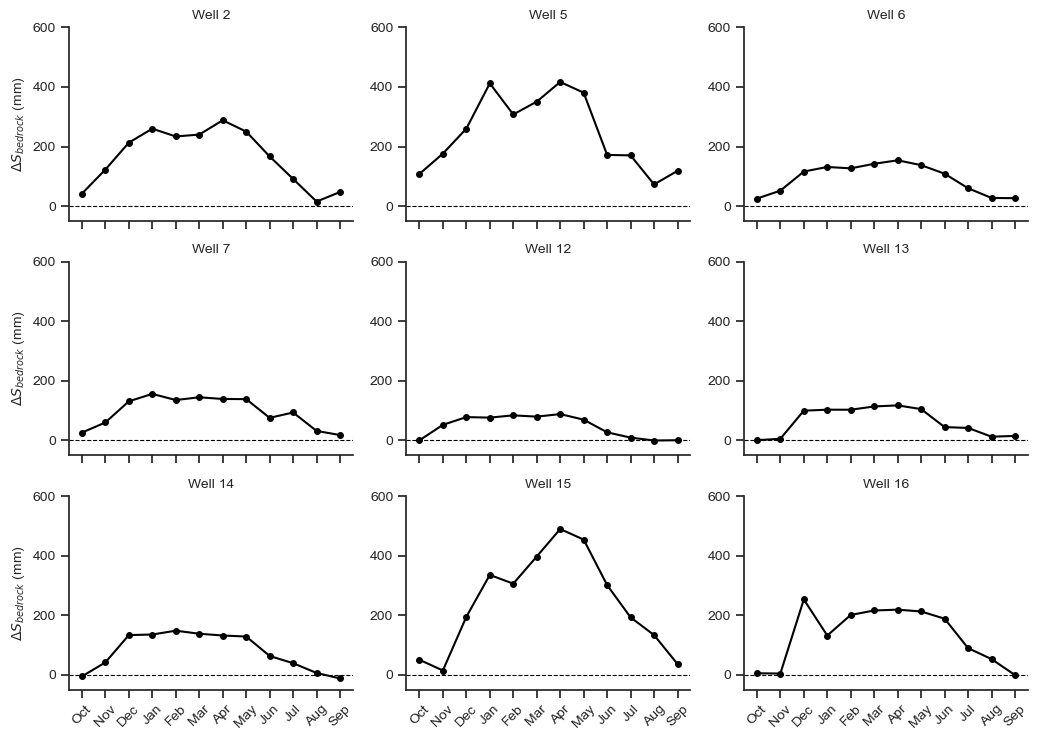

In [3]:
df_stats = storage_ts.dropna(subset=['Total Storage Change (mm)']).copy()

# Order months by the standard October--September water year.
def get_recharge_month(date):
    return date.month - 9 if date.month >= 10 else date.month + 3

df_stats['Recharge_Month'] = df_stats['Date'].apply(get_recharge_month)

monthly_stats = df_stats.groupby(['Hole ID', 'Recharge_Month'])['Total Storage Change (mm)'].median().reset_index()

sorted_holes = sorted(monthly_stats['Hole ID'].unique(), key=lambda x: int(x) if x.isdigit() else x)

ncols = 3
nrows = math.ceil(len(sorted_holes) / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols * 3.5, nrows * 2.5), sharex=True)
axes = axes.flatten()

# Map the numeric sequence back to month names for the x-axis
month_labels = {1:'Oct', 2:'Nov', 3:'Dec', 4:'Jan', 5:'Feb', 6:'Mar', 7:'Apr', 8:'May', 9:'Jun', 10:'Jul', 11:'Aug', 12:'Sep'}

for i, hole in enumerate(sorted_holes):
    ax = axes[i]
    hole_data = monthly_stats[monthly_stats['Hole ID'] == hole].sort_values('Recharge_Month')

    ax.plot(hole_data['Recharge_Month'], hole_data['Total Storage Change (mm)'],
            color='black', lw=1.5, marker='o', markersize=4, label=f'Well {hole}')

    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

    ax.set_xticks(list(month_labels.keys()))
    if i >= len(sorted_holes) - ncols:
        ax.set_xticklabels(list(month_labels.values()), rotation=45)

    if i % ncols == 0:
        ax.set_ylabel(r'$\Delta S_{bedrock}$ (mm)')
    ax.set_title('Well %s'%hole)

    sns.despine(ax=ax)
    ax.set_ylim(-50,600)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()

os.makedirs('./Plots', exist_ok=True)
png_filename_monthly = os.path.join('./Plots', 'rivendell_monthly_dynamics_grid.png')
plt.savefig(png_filename_monthly, dpi=300, bbox_inches='tight')
plt.show()

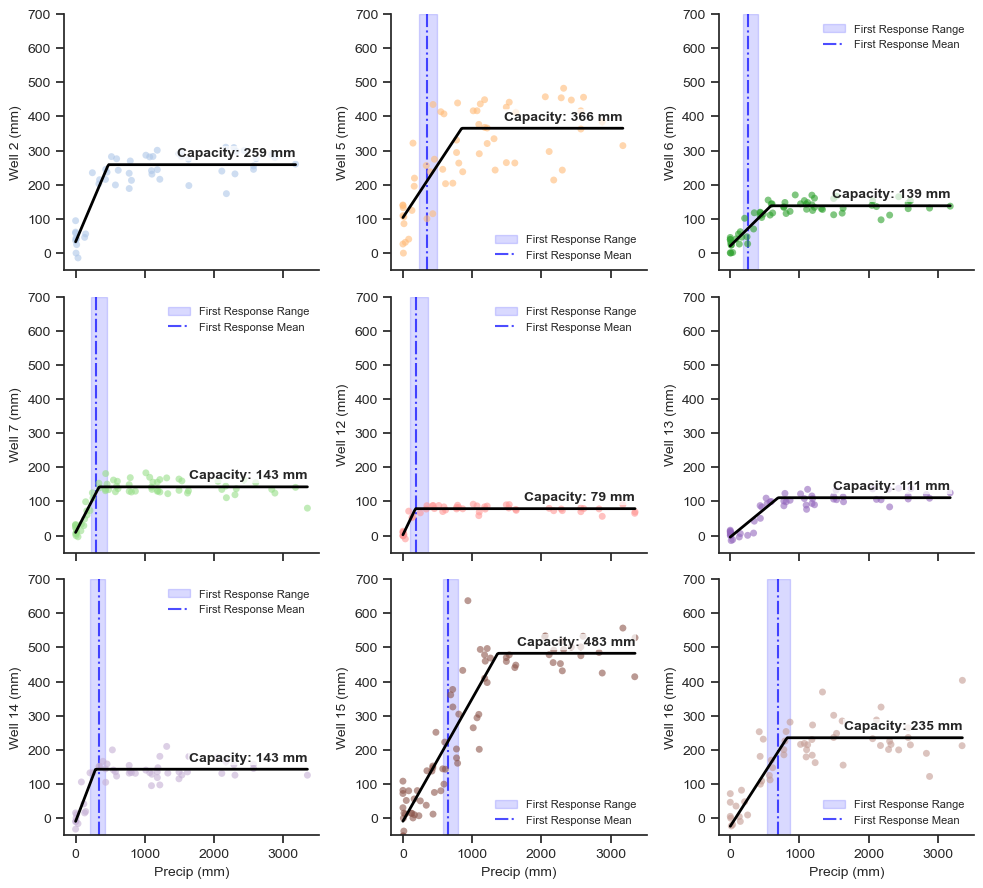

 well  lower_m  upper_m  n  bedrock_capacity_mm  combined_capacity_mm
    2      0.8      9.0 51                259.0                 319.0
    5      0.8     10.0 58                365.5                 425.5
    6      0.8      4.5 63                138.6                 198.6
    7      0.8      4.0 66                142.8                 202.8
   12      0.8      3.0 50                 79.0                 139.0
   13      0.8      5.0 54                111.1                 171.1
   14      0.8      5.0 53                143.3                 203.3
   15      0.8     10.0 76                482.6                 542.6
   16      0.8     10.0 61                235.4                 295.4


In [4]:
font_size = 10
plt.rcParams.update({
    'font.size': font_size,
    'axes.labelsize': font_size,
    'xtick.labelsize': font_size,
    'ytick.labelsize': font_size
})
sns.set_theme(style="ticks")

def piecewise_flat(x, x0, y0, k1):
    return np.where(x < x0, k1 * (x - x0) + y0, y0)

gw_response_stats = {
    '5': {'mean': 348, 'min': 227, 'max': 492},
    '6': {'mean': 263, 'min': 179, 'max': 394},
    '7': {'mean': 301, 'min': 224, 'max': 456},
    '12': {'mean': 190, 'min': 105, 'max': 358},
    '14': {'mean': 332, 'min': 208, 'max': 418},
    '15': {'mean': 651, 'min': 574, 'max': 794},
    '16': {'mean': 693, 'min': 524, 'max': 860}
}

storage_ts['Date_daily'] = storage_ts['Date'].dt.floor('D')

ppt_file = './Data/site_precip_daily.csv'
df_ppt = pd.read_csv(ppt_file, index_col=0, parse_dates=True)
df_ppt.sort_index(inplace=True)

# Calculate cumulative precipitation by the standard October--September water year.
df_ppt['water_year'] = df_ppt.index.year + (df_ppt.index.month >= 10).astype(int)
df_ppt['cum_ppt_mm'] = df_ppt.groupby('water_year')['precip_mm'].cumsum()

df_plot = pd.merge(
    storage_ts,
    df_ppt[['cum_ppt_mm', 'water_year']],
    left_on='Date_daily',
    right_index=True,
    how='inner'
)

start_month = 10
end_month = 5

if start_month > end_month:
    valid_months = list(range(start_month, 13)) + list(range(1, end_month + 1))
else:
    valid_months = list(range(start_month, end_month + 1))

mask = df_plot['Date_daily'].dt.month.isin(valid_months)
df_plot = df_plot[mask].copy()

valid_wells = sorted(df_plot['Hole ID'].unique(), key=int)
cols = 3
rows = int(np.ceil(len(valid_wells) / cols))

fig, axes = plt.subplots(rows, cols, figsize=(10, 3 * rows), sharex=True, sharey=False)
axes = axes.flatten()

colors = well_colors()

# --- DICTIONARY TO STORE CALCULATED CAPACITIES ---
calculated_capacities = {}
fit_records = []

for i, w in enumerate(valid_wells):
    ax = axes[i]
    well_data = df_plot[df_plot['Hole ID'] == w].dropna(subset=['cum_ppt_mm', 'Total Storage Change (mm)'])

    x_data = well_data['cum_ppt_mm'].values
    y_data = well_data['Total Storage Change (mm)'].values

    ax.scatter(x_data, y_data, color=colors[int(w)], s=25, alpha=0.6, edgecolor='none', zorder=2)

    if str(w) in gw_response_stats:
        stats = gw_response_stats[str(w)]
        ax.axvspan(stats['min'], stats['max'], color='blue', alpha=0.15, zorder=0, label='First Response Range')
        ax.axvline(stats['mean'], color='blue', linestyle='-.', alpha=0.7, zorder=1, label='First Response Mean')

    legend_loc = 'upper right'

    if len(x_data) > 4:
        x0_guess = np.median(x_data)
        y0_guess = np.max(y_data)

        x_range = (x0_guess - np.min(x_data))
        if x_range == 0: x_range = 1.0
        k1_guess = (y0_guess - np.min(y_data)) / x_range

        p0 = [x0_guess, y0_guess, k1_guess]
        bounds = ([np.min(x_data), -np.inf, 0], [np.max(x_data), np.inf, np.inf])

        try:
            popt, pcov = curve_fit(piecewise_flat, x_data, y_data, p0=p0, bounds=bounds)
            x0_fit, y0_fit, k1_fit = popt

            # --- SAVE THE CAPACITY FOR THE LATEX TABLE ---
            calculated_capacities[str(w)] = y0_fit
            fit_records.append(dict(well=int(w), n=len(x_data), plateau_precip_mm=x0_fit, bedrock_capacity_mm=y0_fit, soil_capacity_mm=60, combined_capacity_mm=y0_fit+60))

            if y0_fit > 200:
                legend_loc = 'lower right'
            else:
                legend_loc = 'upper right'

            x_fit = np.linspace(np.min(x_data), np.max(x_data), 200)
            y_fit = piecewise_flat(x_fit, *popt)

            ax.plot(x_fit, y_fit, color='black', linewidth=2, linestyle='-', zorder=3)

            ax.text(np.max(x_data), y0_fit + 15, f"Capacity: {y0_fit:.0f} mm",
                    ha='right', va='bottom', fontsize=font_size, fontweight='bold',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))
        except RuntimeError:
            pass

    ax.set_ylabel(f"Well {w} (mm)", fontsize=font_size)
    ax.tick_params(labelsize=font_size)
    ax.grid(False)

    if i >= len(valid_wells) - cols:
        ax.set_xlabel("Precip (mm)", fontsize=font_size)
    else:
        ax.set_xlabel("")

    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(handles, labels, loc=legend_loc, fontsize=8, frameon=False)
    sns.despine(ax=ax)
    ax.set_ylim(-50, 700)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plots_dir = "./Plots"
if not os.path.exists(plots_dir):
    os.makedirs(plots_dir)
plt.savefig(os.path.join(plots_dir, "storage_capacity_horizontal_fit.png"), dpi=300, bbox_inches="tight")
plt.show()
pd.DataFrame(fit_records).to_csv('./Data/vadose_storage_capacities.csv', index=False)
# The manuscript table also records each integration interval and fit sample size.
capacity_table = pd.DataFrame(fit_records).merge(pd.read_csv('./Data/neutron_probe_integration_domains.csv'), on='well')
print(capacity_table[['well','lower_m','upper_m','n','bedrock_capacity_mm','combined_capacity_mm']].round(1).to_string(index=False))


# Export full dataset

In [5]:
# The calibrated depth profiles and calibration/QC tables are exported by
# process_neutron_profiles in the integration cell.
